In [4]:
#Install libraries
!pip install pandas
!pip install numpy
!pip install matplotlib
!pip install seaborn


In [5]:
#Let's import Python libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline
import seaborn as sns

In [6]:
#import csv file
df=pd.read_csv('Sales_Data.csv',encoding='unicode escape')

In [7]:
#Check number of columns and rows
df.shape

(11257, 13)

In [8]:
# see the imported data
df.head(5)        # Show Top 5 Row

,User_ID,Cust_name,Product_ID,Age,Age Group,Gender,State,Zone,Zipcode,Profession,Product_Category,Orders,Amount
0,1002903.0,Anvi,P00125942,27.0,26-35,Female,Maharashtra,West,NaN,Healthcare,Sports,4.0,20500.0
1,1000732.0,Shanta,P00110942,34.0,26-35,Female,Andhra Pradesh,South,NaN,Govt,Sports,2.0,25360.0
2,1001990.0,Sheetal,P00118542,16.0,0-17,Female,Uttar Pradesh,Central,NaN,Automobile,Health,4.0,29350.0
3,1001425.0,Virendra,P00237842,16.0,0-17,M,Karnataka,South,NaN,Construction,Clothing,6.0,23500.0
4,1000588.0,Vishal,P00057942,28.0,26-35,M,Gujarat,West,NaN,Food Processing,Electronics,4.0,23870.0


In [9]:
#Field details and datatype
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 11257 entries, 0 to 11256
Data columns (total 13 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   User_ID           11245 non-null  float64
 1   Cust_name         11245 non-null  str    
 2   Product_ID        11245 non-null  str    
 3   Age               11245 non-null  float64
 4   Age Group         11245 non-null  str    
 5   Gender            11245 non-null  str    
 6   State             11245 non-null  str    
 7   Zone              11245 non-null  str    
 8   Zipcode           0 non-null      float64
 9   Profession        11245 non-null  str    
 10  Product_Category  11245 non-null  str    
 11  Orders            11245 non-null  float64
 12  Amount            11245 non-null  float64
dtypes: float64(5), str(8)
memory usage: 1.7 MB


### Let's Start Data Cleaning


In [10]:
#Deleting Blank Column
df.drop(['Zipcode'],axis=1,inplace=True)

In [11]:
#List of Columns Available
df.columns

Index(['User_ID', 'Cust_name', 'Product_ID', 'Age', 'Age Group', 'Gender',
       'State', 'Zone', 'Profession', 'Product_Category', 'Orders', 'Amount'],
      dtype='str')

In [12]:
#Check for Null Values
pd.isnull(df).sum()

User_ID             12
Cust_name           12
Product_ID          12
Age                 12
Age Group           12
Gender              12
State               12
Zone                12
Profession          12
Product_Category    12
Orders              12
Amount              12
dtype: int64

In [13]:
#Drop Null Values
df.dropna(how='all',inplace=True)

In [14]:
df.shape      

(11245, 12)

In [15]:
#Replace Value From Gender Column
df['Gender']=df['Gender'].replace('M','Male')

In [16]:
# View only Male Gender Data
df[df['Gender']=='Male']

,User_ID,Cust_name,Product_ID,Age,Age Group,Gender,State,Zone,Profession,Product_Category,Orders,Amount
3,1001425.0,Virendra,P00237842,16.0,0-17,Male,Karnataka,South,Construction,Clothing,6.0,23500.0
4,1000588.0,Vishal,P00057942,28.0,26-35,Male,Gujarat,West,Food Processing,Electronics,4.0,23870.0
5,1000588.0,Suuraj,P00057942,28.0,26-35,Male,Himachal Pradesh,Northern,Food Processing,Electronics,3.0,23860.0
8,1003224.0,Kushal,P00205642,35.0,26-35,Male,Uttar Pradesh,Central,Govt,Beauty,4.0,23809.0
11,1003829.0,Harsh,P00200842,34.0,26-35,Male,Delhi,Central,Banking,Health,2.0,23770.0
...,...,...,...,...,...,...,...,...,...,...,...,...
11249,1005446.0,Sheetal,P00297742,53.0,51-55,Male,Gujarat,West,Healthcare,Health,3.0,382.0
11250,1005446.0,Sheetal,P00297742,53.0,51-55,Male,Madhya Pradesh,Central,Healthcare,Health,2.0,382.0
11252,1000695.0,Manning,P00296942,19.0,18-25,Male,Maharashtra,West,Chemical,Health,1.0,370.0
11253,1004089.0,Reichenbach,P00171342,33.0,26-35,Male,Haryana,Northern,Healthcare,Health,5.0,367.0


## --> Now Let's Learn EDA - Exploratory Data Analysis

In [15]:
# describe() method returns description of the data in the DataFrame (i.e. count, mean, std, etc)
df.describe()

,User_ID,Age,Orders,Amount
count,1.124500e+04,11245.000000,11245.000000,11245.000000
mean,1.003004e+06,35.415651,3.500311,9461.934237
std,1.716207e+03,12.756369,1.713706,5234.426634
min,1.000001e+06,12.000000,1.000000,188.000000
25%,1.001492e+06,27.000000,2.000000,5443.000000
50%,1.003065e+06,33.000000,4.000000,8109.000000
75%,1.004429e+06,43.000000,5.000000,12683.000000
max,1.006040e+06,92.000000,6.000000,29350.000000


In [17]:
# Use describe for specific columns
df[['Age','Orders','Amount']].describe()

,Age,Orders,Amount
count,11245.000000,11245.000000,11245.000000
mean,35.415651,3.500311,9461.934237
std,12.756369,1.713706,5234.426634
min,12.000000,1.000000,188.000000
25%,27.000000,2.000000,5443.000000
50%,33.000000,4.000000,8109.000000
75%,43.000000,5.000000,12683.000000
max,92.000000,6.000000,29350.000000


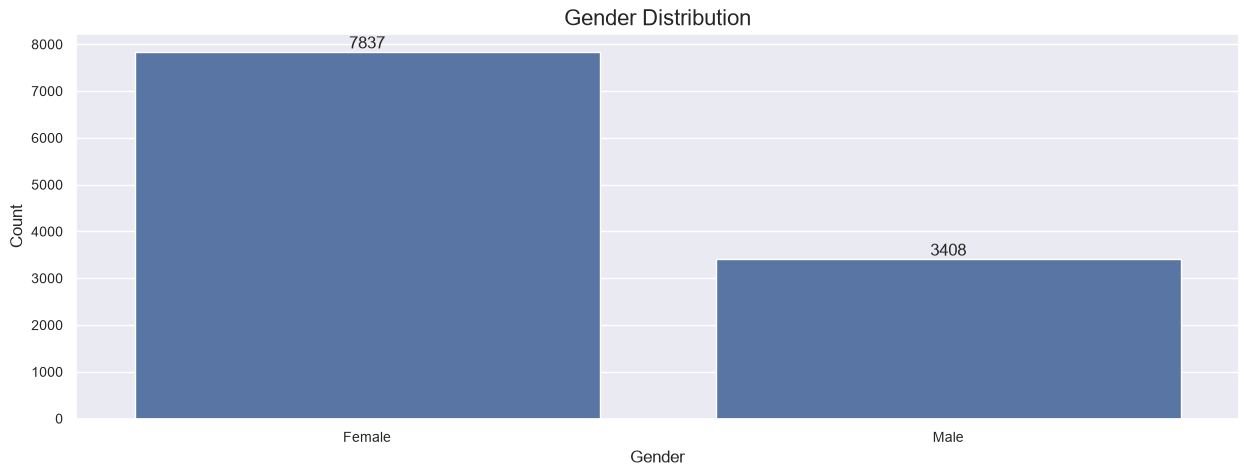

In [45]:
#Total Transactions count by Gender Wise in Bar Chart
ax=sns.countplot(x ='Gender',data = df)
for bars in ax.containers:
    ax.bar_label(bars)
    ax.set_title('Gender Distribution',fontsize=16)
    ax.set_xlabel('Gender',fontsize=12)
    ax.set_ylabel('Count',fontsize=12)
    ax.tick_params(axis='both',labelsize=10)
plt.show()

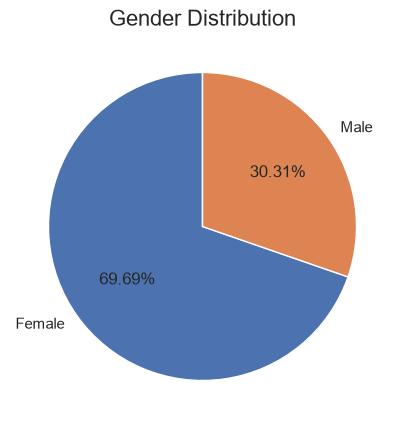

In [46]:
#Gender Wise Distribution in Pie Chart
gender_counts=df['Gender'].value_counts()
plt.pie(
    gender_counts,                           #Data Counts
    labels=gender_counts.index,              #Labels(eg: 'Male', 'Female')
    autopct='%.2f%%',                       #Show Percentage(2 decimals)
    startangle=90                            #Show better orientation   
)
plt.title("Gender Distribution",fontsize=16)
plt.show()

    

In [45]:
#Group by use
df.groupby('Gender',as_index=False)['Amount'].sum()

,Gender,Amount
0,Female,74461610.49
1,Male,31937840.00


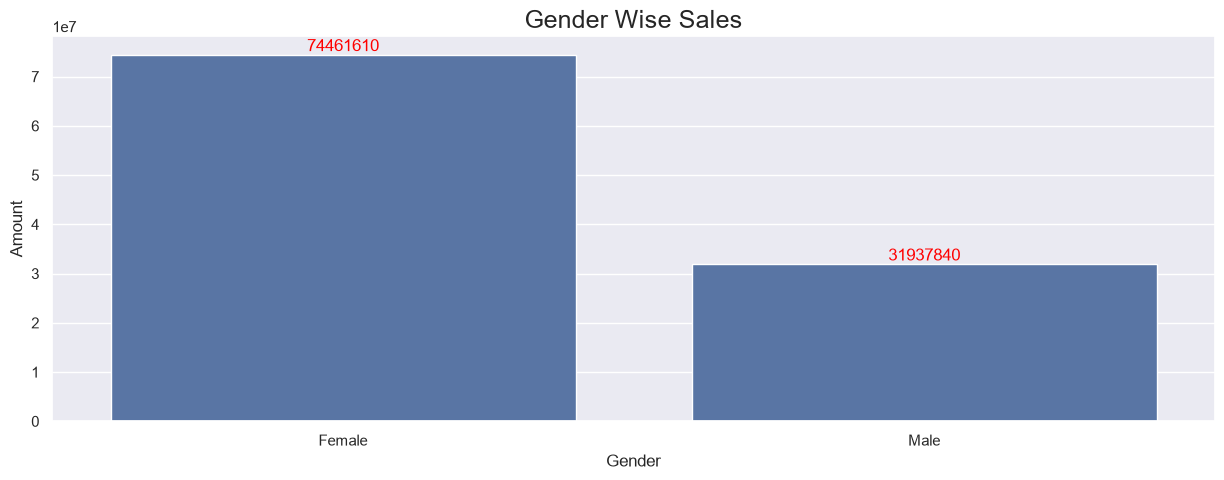

In [47]:
#Gender Wise Total Sales Amount
gen_wise_sales=df.groupby('Gender',as_index=False)['Amount'].sum().sort_values(by='Amount',ascending=False)
ax=sns.barplot(x='Gender',y='Amount',data=gen_wise_sales)
for bars in ax.containers:
    ax.bar_label(bars,fmt='%.0f',fontsize=12,color='Red')
plt.title('Gender Wise Sales', fontsize=18)
plt.show()

### --> Age Group by Total Transaction

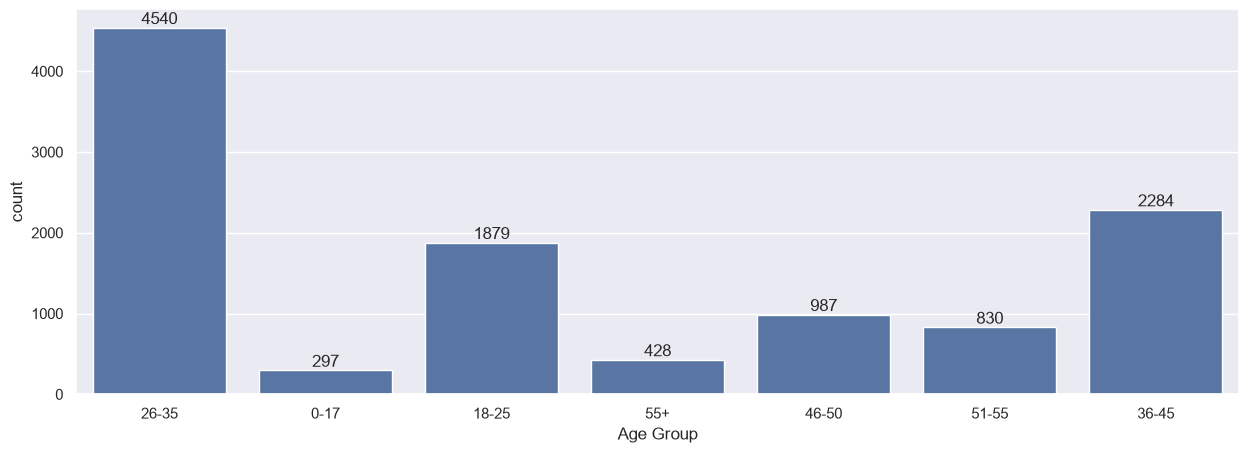

In [48]:
#Age Group by Trasaction Count in Bar Chart
ax=sns.countplot(x ='Age Group', data = df)
for bars in ax.containers:            #Show Data Labels
    ax.bar_label(bars)
plt.show()

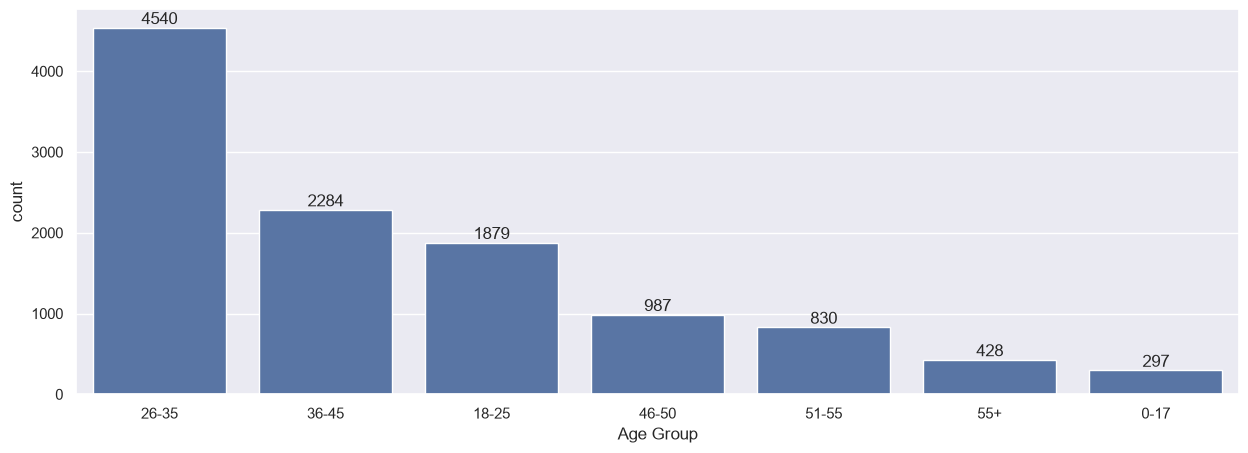

In [49]:
#Age Group Wise Transaction Count (Sorting)
sort_age=df['Age Group'].value_counts().sort_values(ascending=False)
index_order=sort_age.index
ax=sns.countplot(x ='Age Group', data = df, order = index_order)
for bars in ax.containers:            #Show Data Labels
    ax.bar_label(bars)
plt.show()

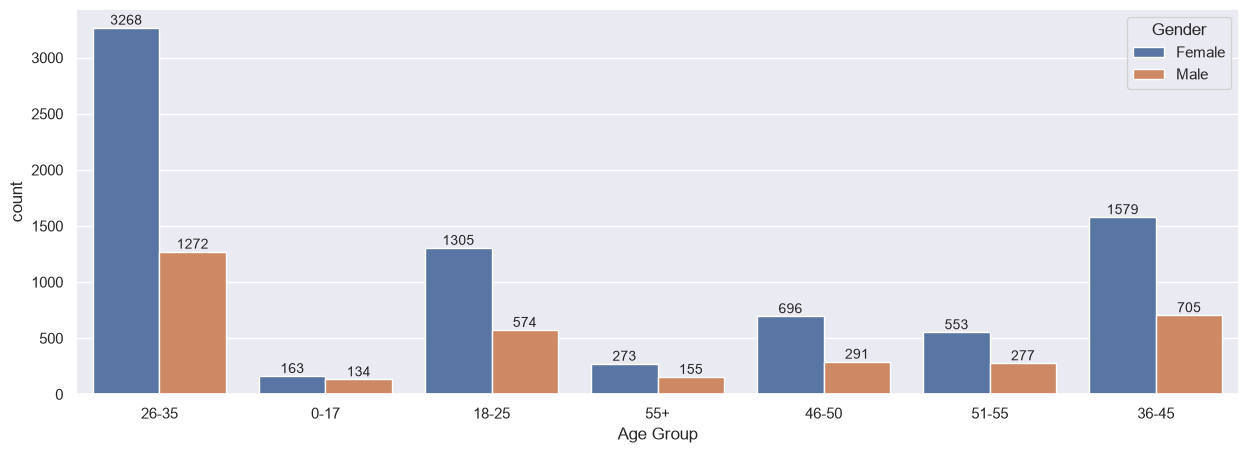

In [50]:
#Age Group and Gender Wise Transaction Distribution
ax=sns.countplot(data = df, x = 'Age Group', hue = 'Gender')
for bars in ax.containers:
    ax.bar_label(bars,fontsize=10)
plt.show()

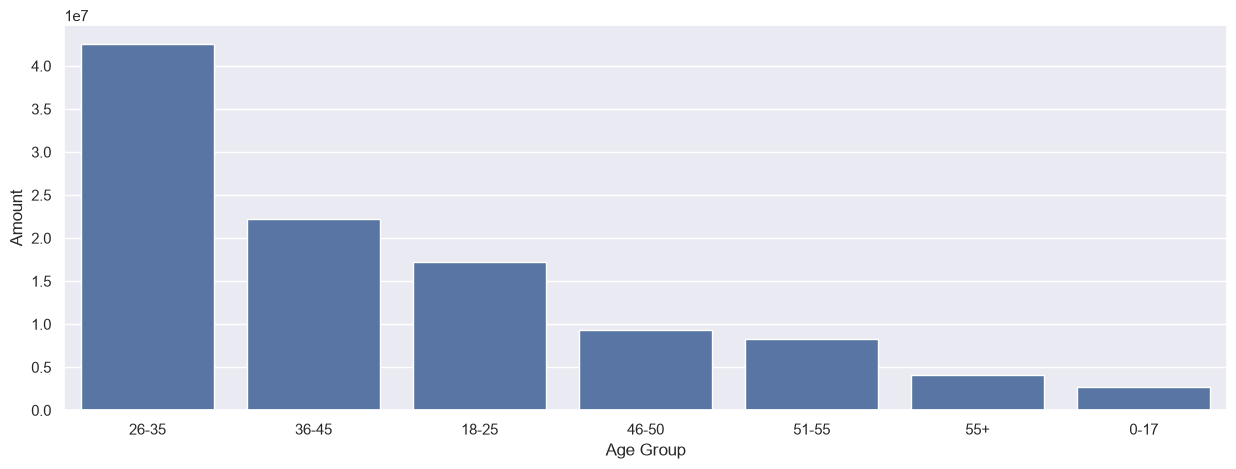

In [51]:
#Age Group Wise Total Amount
age_sales=df.groupby(['Age Group'],as_index=False)['Amount'].sum().sort_values(by='Amount',ascending=False)
sns.barplot(x='Age Group',y='Amount',data=age_sales)
plt.show()

### --> State Wise Sales

In [34]:
order_state=df.groupby(['State'],as_index=False)['Orders'].sum().sort_values(by='Orders',ascending=False).head(5)
print(order_state)

             State  Orders
14   Uttar Pradesh  6669.0
10     Maharashtra  5328.0
7        Karnataka  4506.0
2            Delhi  3893.0
9   Madhya Pradesh  3217.0


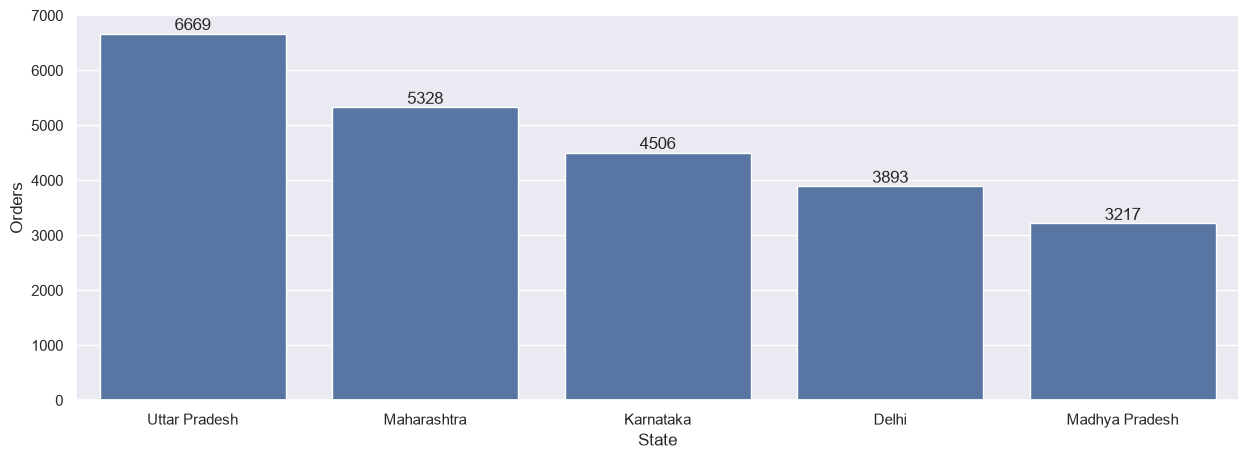

In [52]:
#Order Wise Top 5 State
order_wise_state=df.groupby(['State'],as_index=False)['Orders'].sum().sort_values(by='Orders',ascending=False).head(5)
px=sns.barplot(x='State',y='Orders',data=order_wise_state)
for bars in px.containers:
    px.bar_label(bars)
plt.show()

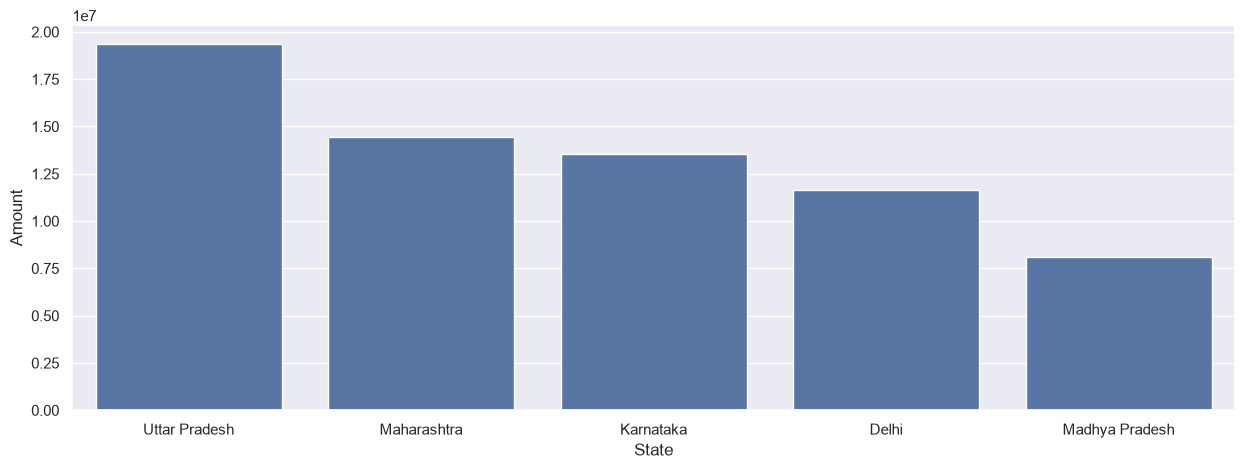

In [54]:
#Amount Wise Top 5 State
amount_wise_state=df.groupby(['State'],as_index=False)['Amount'].sum().sort_values(by='Amount',ascending=False).head(5)

sns.set(rc={'figure.figsize':(15,5)})                             # Bars Figure set 
sns.barplot(data=amount_wise_state, x='State',y='Amount')

plt.show()

From above graphs we can see that most of the orders & total sales/amount are from Uttar Pradesh, Maharashtra and Karnataka respectively

### --> Product Category Analysis

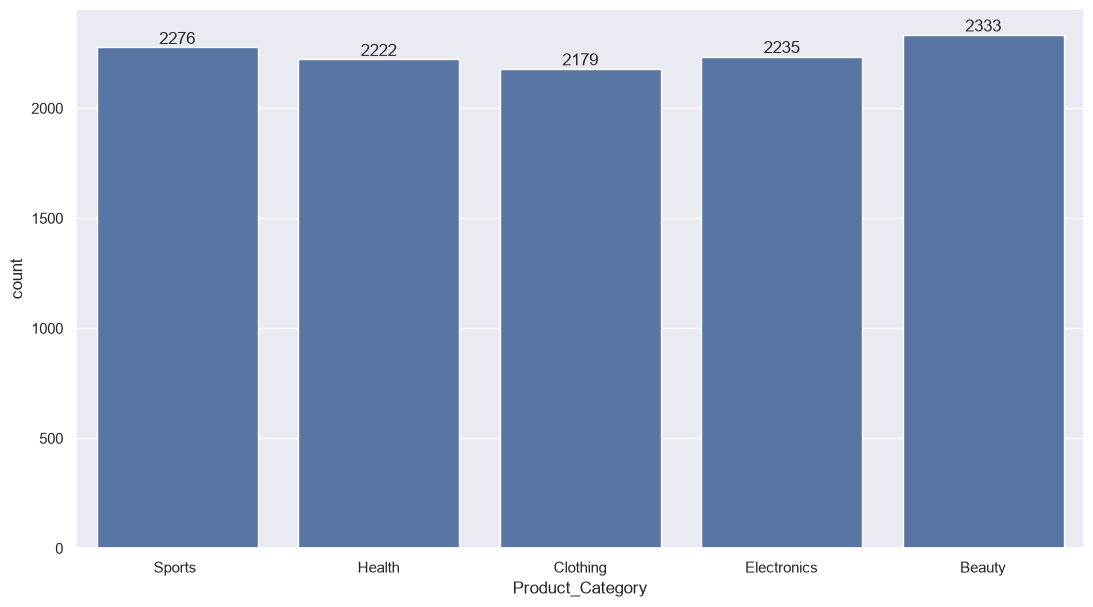

In [64]:
#Product category wise Transactions count
ax=sns.countplot(data=df, x ='Product_Category')

#sns.set(rc={'figure.figsize':(13,7)})
for bars in ax.containers:
    ax.bar_label(bars)
plt.show()

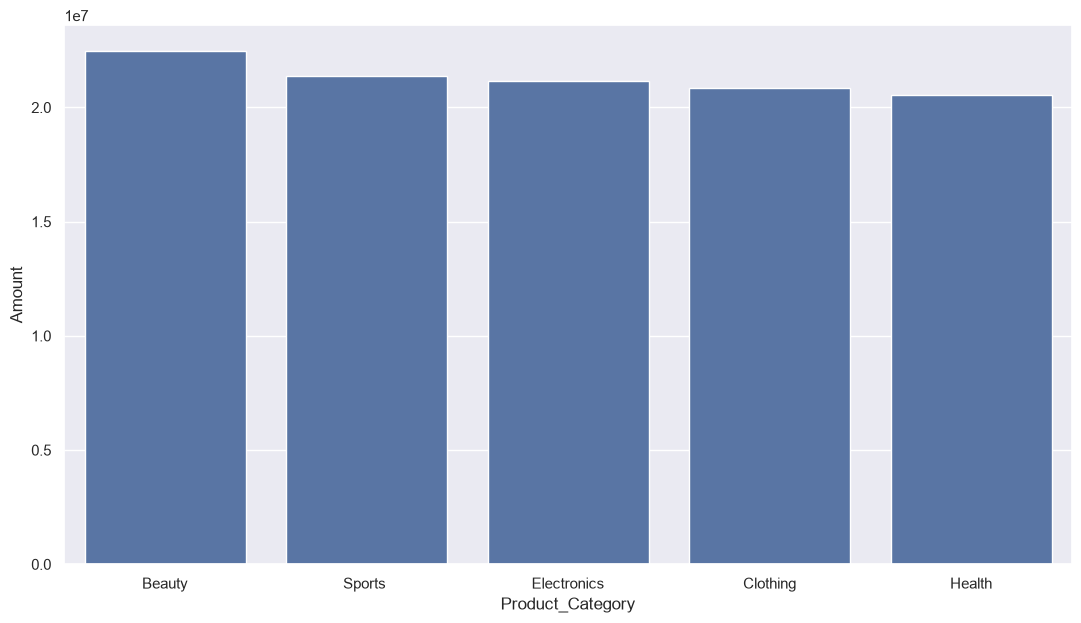

In [70]:
#Amount wise Product Category in Bar Chart
product_wise_sales=df.groupby(['Product_Category'],as_index=False)['Amount'].sum().sort_values(by='Amount',ascending=False)

sns.barplot(data=product_wise_sales, x='Product_Category', y='Amount')
plt.show()

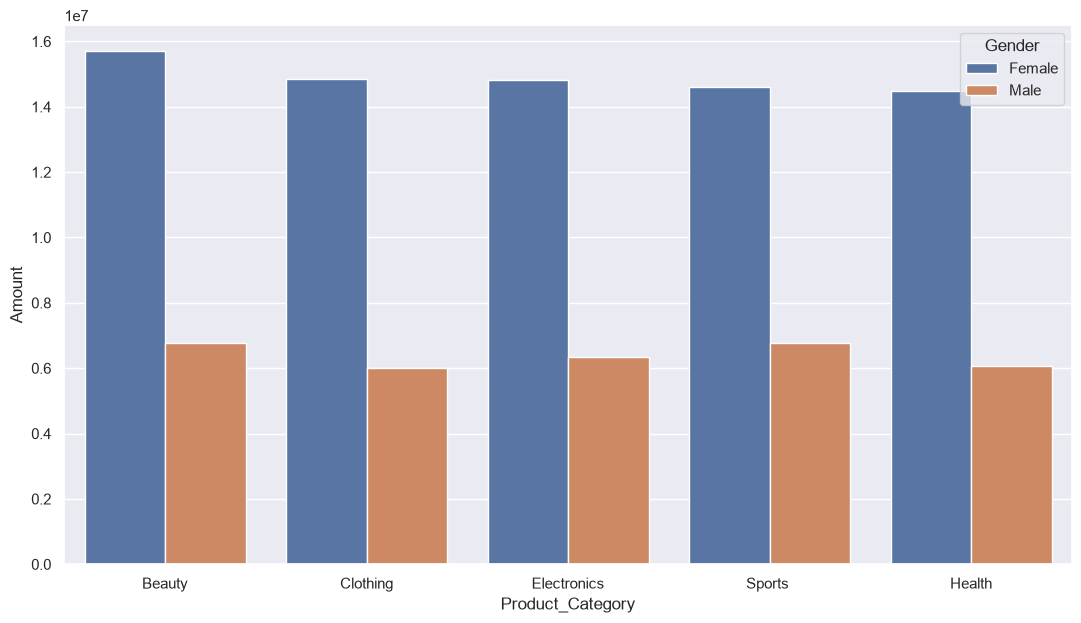

In [72]:
#Product category and Gender wise Transactions count
product_gender_wise_count=df.groupby(['Product_Category','Gender'],as_index=False)['Amount'].sum().sort_values(by='Amount',ascending=False)
sns.barplot(data=product_gender_wise_count, x='Product_Category', y='Amount',hue='Gender')

plt.show()

*From above graphs we can see that most of the buyers are Female

### --> Profession Wise Analysis

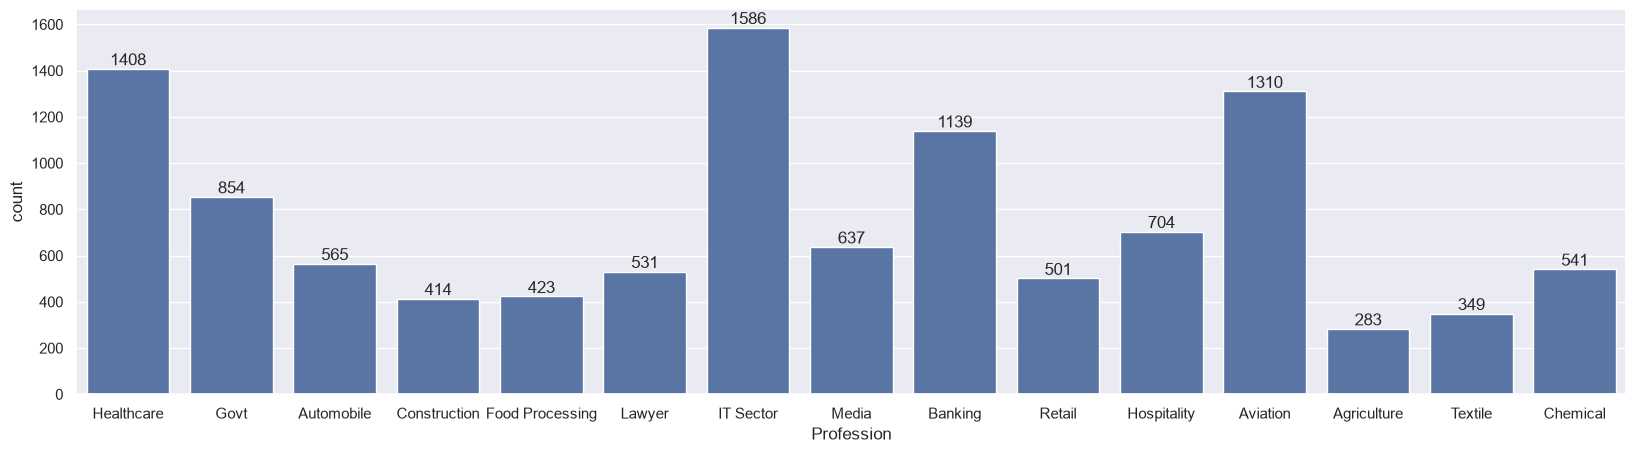

In [77]:
#Profession wise Transactions count
ax=sns.countplot(data=df, x='Profession')
sns.set(rc={'figure.figsize':(25,5)})
for bars in ax.containers:
    ax.bar_label(bars)
plt.show()

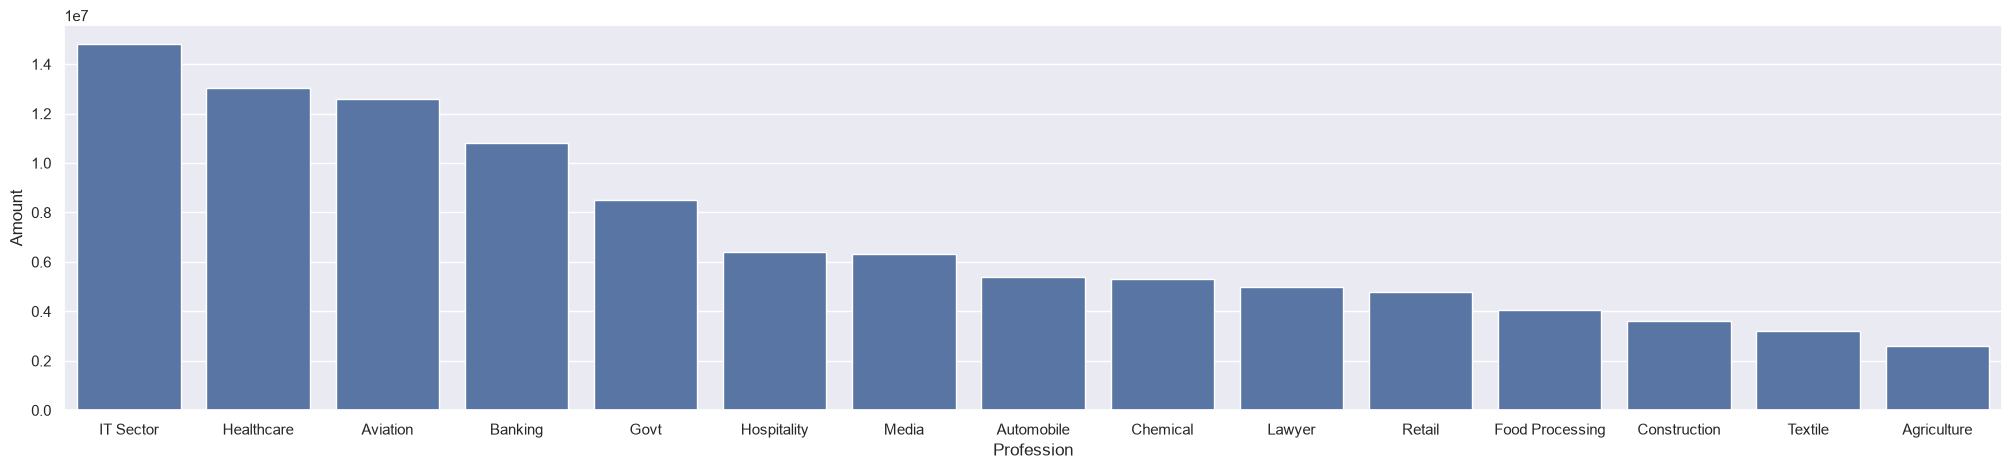

In [86]:
#Amount Wise Top Professions
profession_wise_sales=df.groupby(['Profession'],as_index=False)['Amount'].sum().sort_values(by='Amount',ascending=False)
ax=sns.barplot(data=profession_wise_sales, x='Profession', y='Amount')


plt.show()

From above graphs we can see that most of the buyers are working in IT, Healthcare and Aviation sector

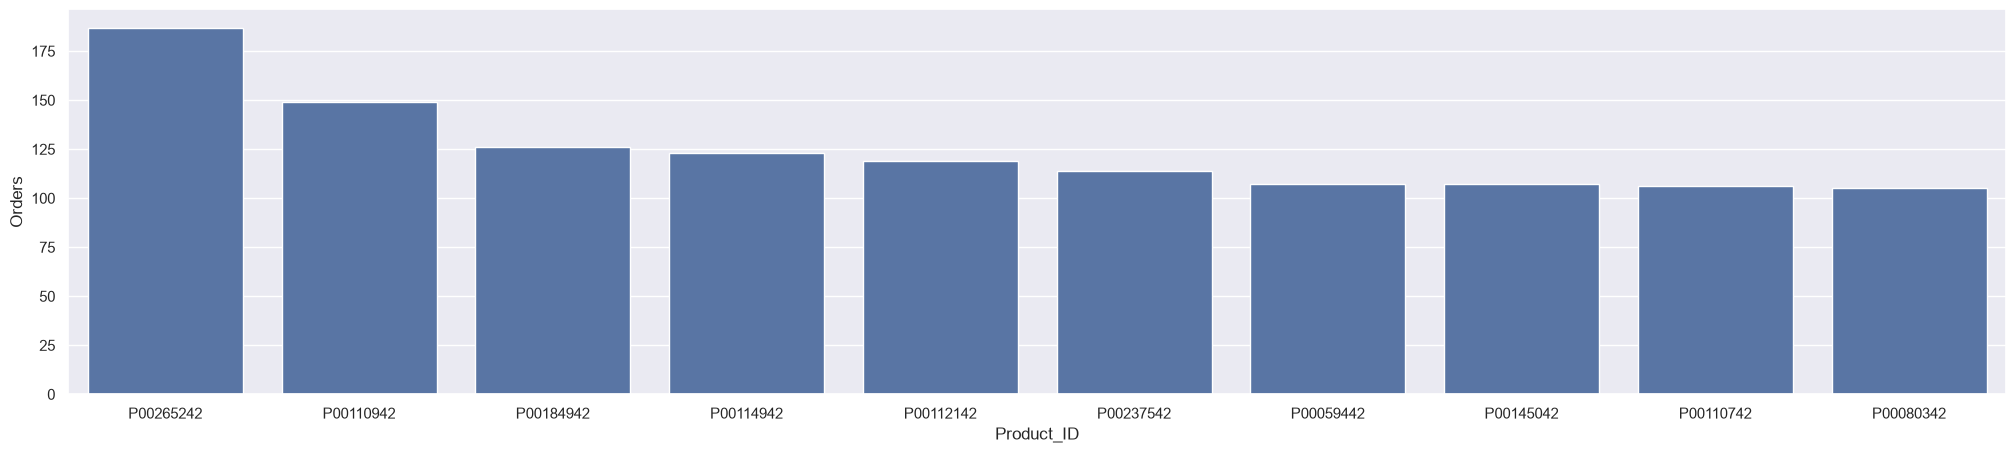

In [87]:
#Order Wise Top 10 Products
top_10_product=df.groupby(['Product_ID'],as_index=False)['Orders'].sum().sort_values(by='Orders',ascending=False).head(10)
sns.barplot(data=top_10_product, x='Product_ID', y='Orders')
plt.show()


## Conclusion:-

### *Female age group 26-35 yrs from UP,  Maharastra and Karnataka working in IT, Healthcare and Aviation are more likely to buy products from Beauty, Sports and Electronics.*